# Training an LSTM for synchronized anomaly detection

## Creating a synthetic dataset

We create a synthetic dataset (*i.e.* a noisy periodic but non-trivial signal):

In [1]:
from make_dataset import generate_signal, to_sequences

# Dataset parameters
LENGTH = 500
SAMPLING_FREQUENCY = 10
NOISE = 0.1
TRAIN_RATIO = 0.8

# Dataset and train/validation split
signal = generate_signal(LENGTH, SAMPLING_FREQUENCY, NOISE)
X = signal["value"]
time = signal["time"]
num_points = len(X)
split_idx = int(TRAIN_RATIO * num_points)
t_train, X_train = time[:split_idx], X[:split_idx]
t_val, X_val = time[split_idx:], X[split_idx:]

Plot the signal:

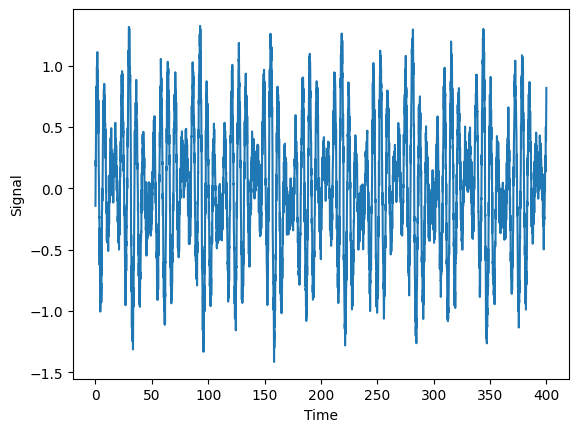

In [2]:
import matplotlib.pyplot as plt

plt.plot(t_train, X_train)
plt.xlabel("Time")
plt.ylabel("Signal")
plt.show()

## Train the model

Parameters of the LSTM:

In [3]:
# Model parameters
WINDOW_SIZE = 64
ACTIVATION = 'relu'
LSTM_1_UNITS = 32
LSTM_2_UNITS = 16
DROPOUT_RATE = 0.2
BATCH_SIZE = 64
EPOCHS = 50

Window the training and validation sets:

In [4]:
# Window the training and validation sets
X_train, y_train = to_sequences(X_train, WINDOW_SIZE)
X_val, y_val     = to_sequences(X_val,   WINDOW_SIZE)

Only make the small GPU available to avoid locking the big one:

In [5]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "0" # use only the small GPU

Set up the LSTM with the selected parameters:

In [6]:
import tensorflow as tf

# Reset states generated by Keras
tf.keras.backend.clear_session()

# Build the input layer and add it to the model with a shape of (WINDOW_SIZE, 1)
input_layer = tf.keras.layers.Input(shape=(WINDOW_SIZE, 1))
lstm = tf.keras.models.Sequential([input_layer])

# Add LSTM layers
lstm.add(tf.keras.layers.LSTM(units=LSTM_1_UNITS,
                                 activation=ACTIVATION,
                                 return_sequences=True))

# Add dropout layer after the first LSTM
lstm.add(tf.keras.layers.Dropout(DROPOUT_RATE))

# Add second LSTM layer and another dropout layer
lstm.add(tf.keras.layers.LSTM(units=LSTM_2_UNITS,
                                 activation=ACTIVATION,
                                 return_sequences=False))
lstm.add(tf.keras.layers.Dropout(DROPOUT_RATE))

# Add output layer
lstm.add(tf.keras.layers.Dense(1))

# Compile the model
lstm.compile(optimizer='adam', loss='mse')
                              
# Early stopping
early_stopping = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, min_delta=0.0001, restore_best_weights=True)

2025-03-03 11:25:07.282764: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-03-03 11:25:07.311093: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1740997507.326091 1522281 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1740997507.330412 1522281 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-03-03 11:25:07.346238: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instr

Train the LSTM with early stopping using the validation set:

In [7]:
# Train the model
history = lstm.fit(x=X_train, y=y_train, epochs=EPOCHS,
                   validation_data=(X_val, y_val),
                   shuffle=True,
                   batch_size=BATCH_SIZE,
                   callbacks=[early_stopping],
                   verbose=1)

Epoch 1/50


I0000 00:00:1740997517.185280 1522473 service.cc:148] XLA service 0x7fa968004c10 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1740997517.185315 1522473 service.cc:156]   StreamExecutor device (0): NVIDIA A100 80GB PCIe, Compute Capability 8.0
2025-03-03 11:25:17.231691: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1740997517.472195 1522473 cuda_dnn.cc:529] Loaded cuDNN version 90300


11/62 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.2401

I0000 00:00:1740997518.647937 1522473 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


62/62 ━━━━━━━━━━━━━━━━━━━━ 6s 47ms/step - loss: 0.1897 - val_loss: 0.0297
Epoch 2/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0515 - val_loss: 0.0183
Epoch 3/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0361 - val_loss: 0.0159
Epoch 4/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0327 - val_loss: 0.0165
Epoch 5/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0300 - val_loss: 0.0186
Epoch 6/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0298 - val_loss: 0.0136
Epoch 7/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0292 - val_loss: 0.0148
Epoch 8/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0280 - val_loss: 0.0135
Epoch 9/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0274 - val_loss: 0.0161
Epoch 10/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0259 - val_loss: 0.0134
Epoch 11/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0263 - val_loss: 0.0145
Epoch 12/50
62/62 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0288 - val_l

Plot the training history:

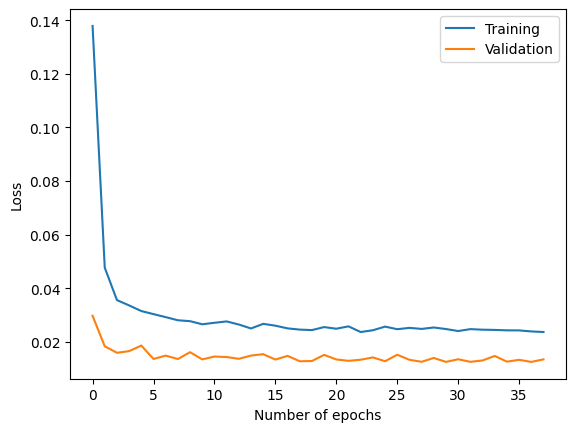

In [8]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.xlabel("Number of epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()

The LSTM uses the last `WINDOW_SIZE=64` points to predict the next one. Show a prediction on the validation set:

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 423ms/step


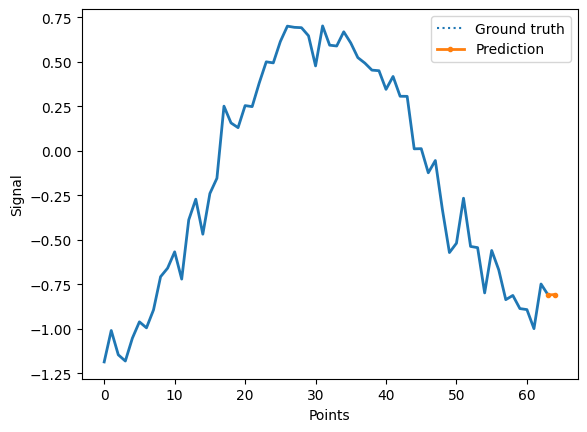

In [9]:
# Make a single prediction in the validation set for the example
idx = 100
X_pred_val = lstm.predict(X_val[idx].reshape(1, WINDOW_SIZE))[0,0]

# Show the single-step prediction
plt.plot(X_val[idx], color='tab:blue', lw=2)
plt.plot([WINDOW_SIZE-1, WINDOW_SIZE], [X_val[idx][-1], y_val[idx]], color='tab:blue', linestyle='dotted', label='Ground truth')
plt.plot([WINDOW_SIZE-1, WINDOW_SIZE], [X_val[idx][-1], X_pred_val], color='tab:orange', lw=2, marker='.', label='Prediction')
plt.xlabel("Points")
plt.ylabel("Signal")
plt.legend()
plt.show()

Save the trained model as a Keras file for later use:

In [10]:
lstm.save("lstm.keras")